# CNN Development on a Custom Dataset: Weather Image Classification

**Student ID:** 22-48324-3 &nbsp;|&nbsp; **Course:** Computer Vision & Pattern Recognition
**Task:** Design, train and evaluate a custom CNN (built from scratch in PyTorch) for multi-class weather-condition image classification.

**Notebook outline**
1. Import Libraries
2. Load and Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Evaluate Model on Test Set
7. Visualizations (Loss/Accuracy Curves)
8. Analysis & Discussion of Results
9. Conclusions & Future Work
10. Save and Load Trained Model Weights

## 1. Import Libraries

In [1]:
import os, random, time, copy, textwrap
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

ImageFile.LOAD_TRUNCATED_IMAGES = True   

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")

PyTorch version: 2.11.0+cu130
Using device   : cuda | Tesla T4


## 2. Load and Explore Dataset

### Dataset description
- **Name:** Weather Dataset / Weather Image Recognition (Kaggle, by Jehan Bhathena).
- **Task:** Multi-class classification of the weather condition shown in a photograph.
- **Classes (11):** dew, fogsmog, frost, glaze, hail, lightning, rain, rainbow, rime, sandstorm, snow (the exact list read from the folders is printed below).
- **Format:** colour photographs of different sizes, stored one folder per class. The dataset has **no official train/validation/test split**, so a stratified split is created in Section 3.
- **Why this dataset:** weather phenomena are visually subtle and several classes look alike (frost vs. rime vs. glaze, fog vs. rain), the classes are **not perfectly balanced**, and image sizes differ. This makes it a more realistic test of a CNN than a clean, balanced dataset. The size is also suitable for training a custom CNN from scratch on a free Kaggle GPU.

In [2]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def find_dataset_root(search_root="/kaggle/input"):
    """Return the folder whose sub-folders are the class folders (>=3 sub-folders that directly contain images)."""
    best, best_n = None, 0
    for dirpath, dirnames, _ in os.walk(search_root):
        n_classes, n_images = 0, 0
        for d in dirnames:
            files = [f for f in os.listdir(os.path.join(dirpath, d)) if f.lower().endswith(IMG_EXT)]
            if files:
                n_classes += 1; n_images += len(files)
        if n_classes >= 3 and n_images > best_n:
            best, best_n = dirpath, n_images
    return best

DATA_DIR = find_dataset_root() or "./dataset"    
print("Dataset folder:", DATA_DIR)
assert os.path.isdir(DATA_DIR), "Dataset not found - did you add it as an input?"

Dataset folder: /kaggle/input/datasets/jehanbhathena/weather-dataset/dataset


Classes (11): ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']
Images found: 6862 | unreadable files removed: 0 | usable: 6862


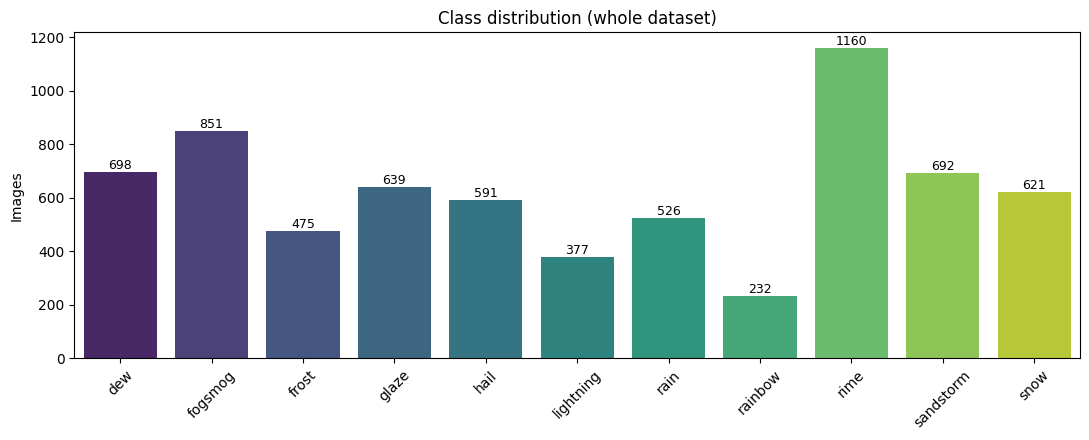

Largest class: rime (1160) | smallest class: rainbow (232) | imbalance ratio: 5.0x
Image width range (300-image sample): 162-1920 px | height range: 91-1200 px -> sizes vary, so every image is resized.


In [3]:
raw = datasets.ImageFolder(DATA_DIR)
class_names = raw.classes
NUM_CLASSES = len(class_names)

def is_ok(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except Exception:
        return False

clean_samples = [s for s in raw.samples if is_ok(s[0])]
print(f"Classes ({NUM_CLASSES}): {class_names}")
print(f"Images found: {len(raw.samples)} | unreadable files removed: {len(raw.samples) - len(clean_samples)} | usable: {len(clean_samples)}")

all_targets = np.array([t for _, t in clean_samples])
class_counts = np.bincount(all_targets, minlength=NUM_CLASSES)

plt.figure(figsize=(11, 4.5))
ax = sns.barplot(x=class_names, y=class_counts, hue=class_names, legend=False, palette="viridis")
ax.set_title("Class distribution (whole dataset)"); ax.set_ylabel("Images")
for i, c in enumerate(class_counts): ax.text(i, c, str(c), ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print(f"Largest class: {class_names[class_counts.argmax()]} ({class_counts.max()}) | "
      f"smallest class: {class_names[class_counts.argmin()]} ({class_counts.min()}) | "
      f"imbalance ratio: {class_counts.max() / class_counts.min():.1f}x")

sizes = [Image.open(clean_samples[i][0]).size for i in random.sample(range(len(clean_samples)), 300)]
ws, hs = zip(*sizes)
print(f"Image width range (300-image sample): {min(ws)}-{max(ws)} px | height range: {min(hs)}-{max(hs)} px -> sizes vary, so every image is resized.")

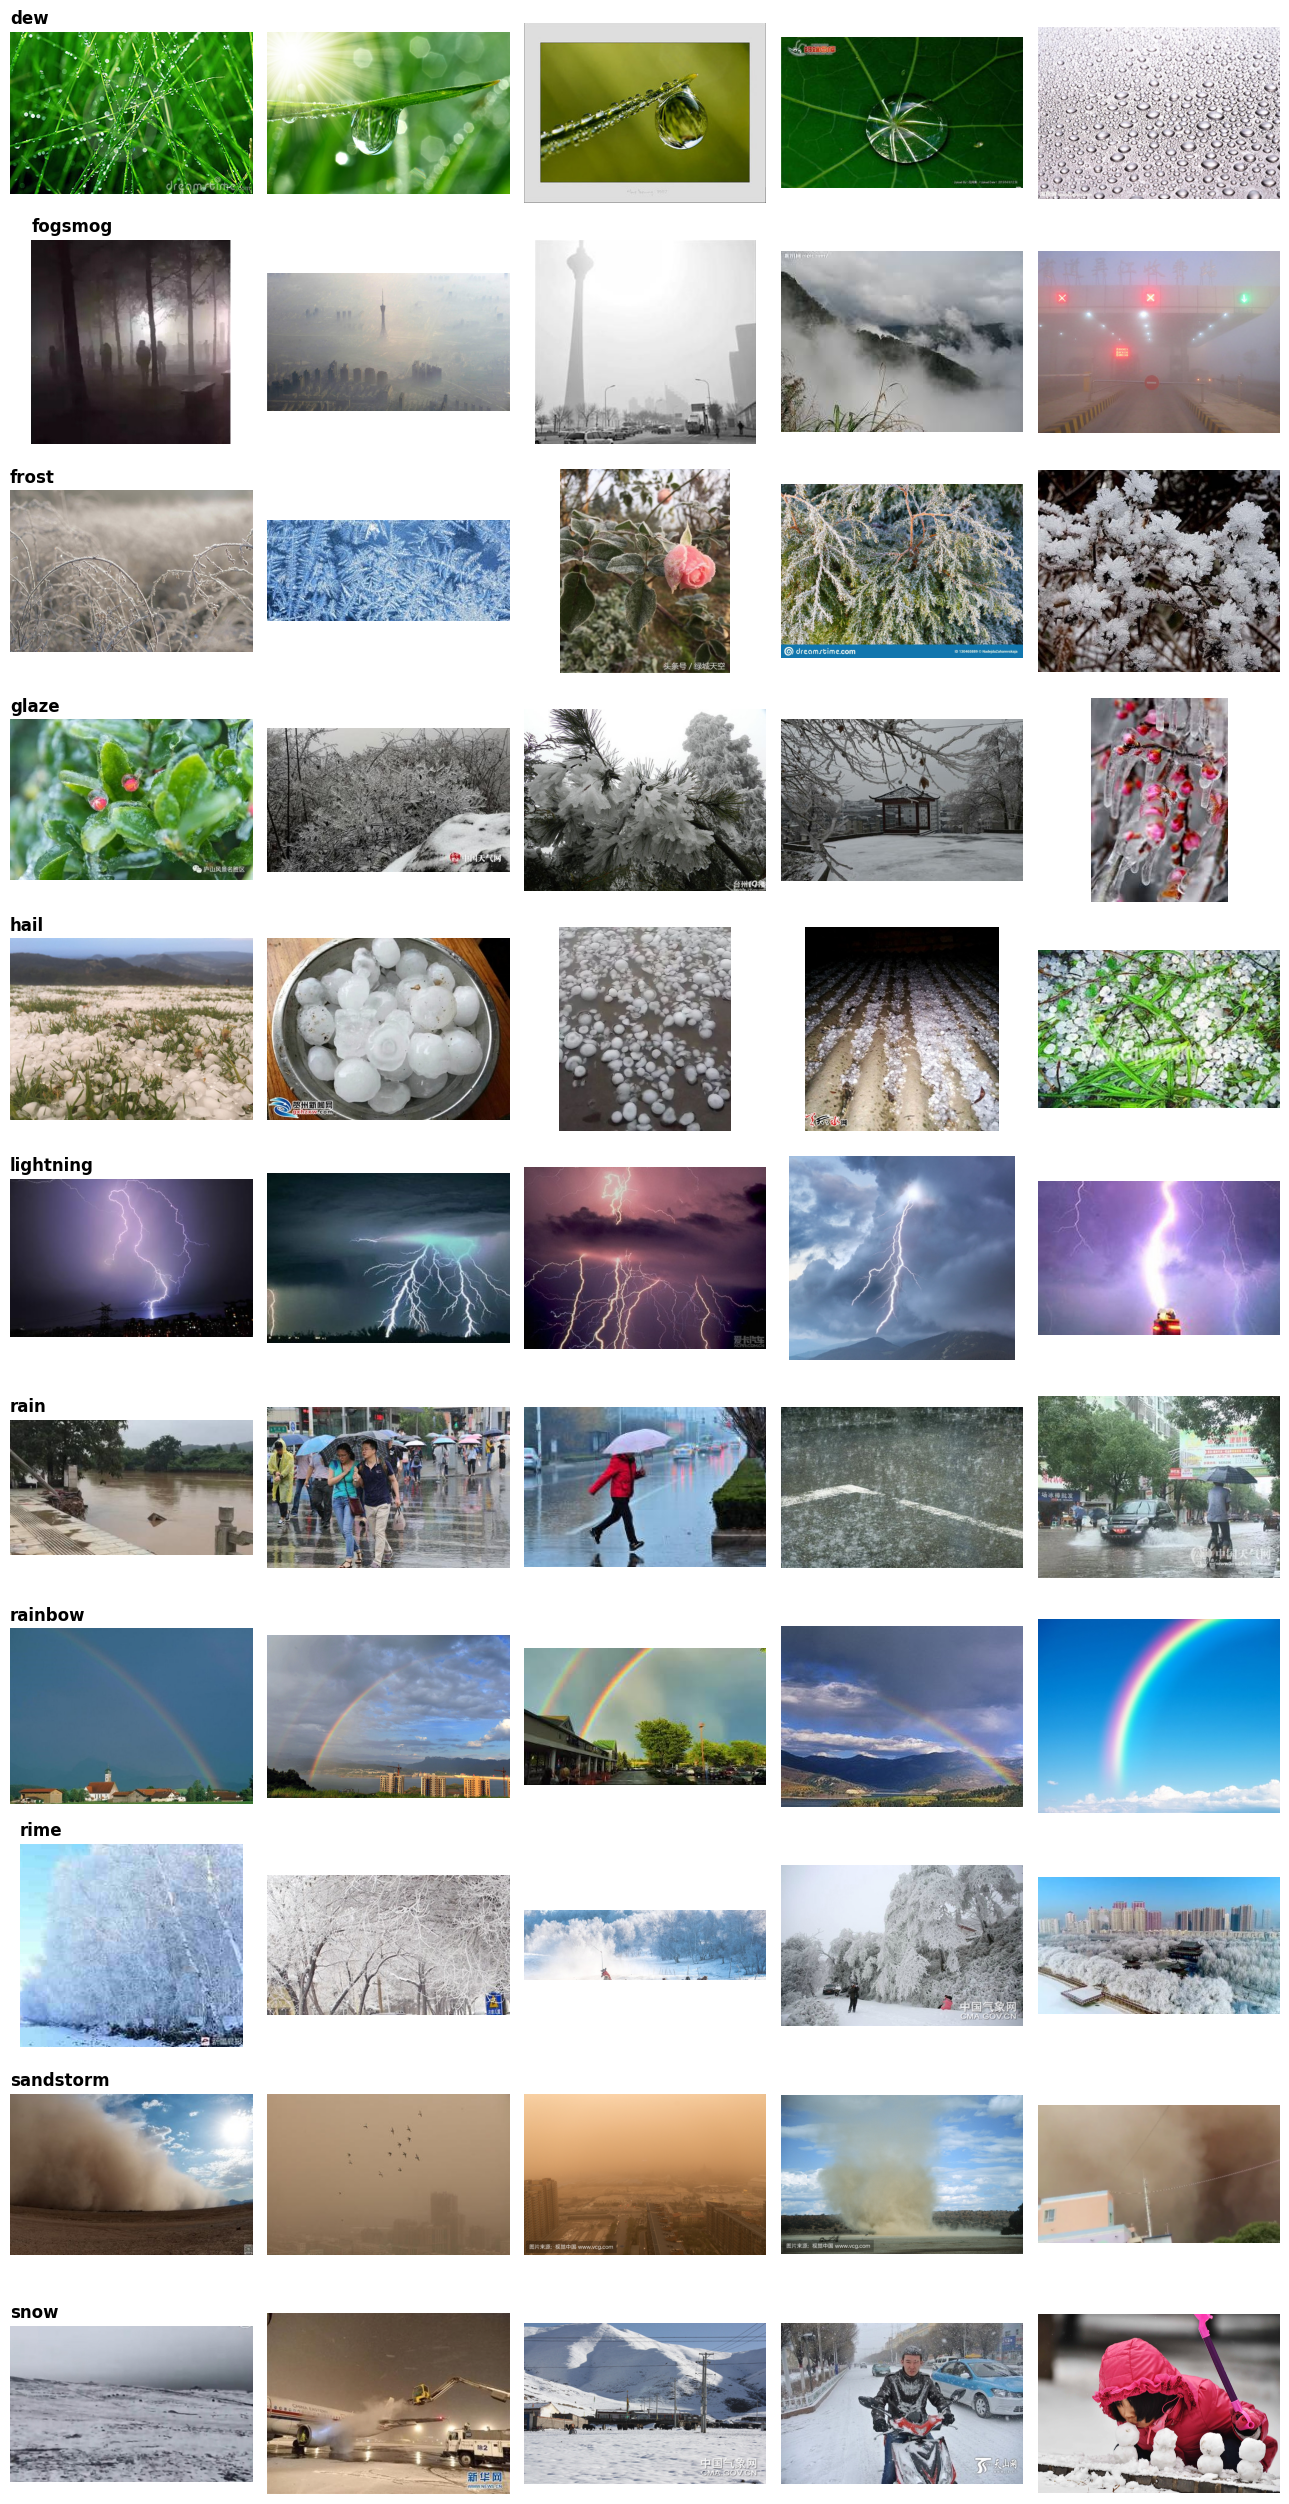

In [4]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(13, 2.3 * NUM_CLASSES))
for c in range(NUM_CLASSES):
    paths = random.sample([p for p, t in clean_samples if t == c], 5)
    for j, p in enumerate(paths):
        axes[c, j].imshow(Image.open(p).convert("RGB")); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(class_names[c], loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Data Preprocessing & Augmentation

**Preprocessing (all splits):** resize to **192x192** (a compromise between detail and speed on a free GPU; the higher resolution keeps the fine texture that separates frost, rime and glaze), convert to tensor (scales pixels to [0,1]), and normalise with the ImageNet mean/std so that each channel is roughly zero-centred, which makes optimisation more stable. Images come in different sizes, so resizing also gives every batch the same shape.

**Augmentation (training only):** random resized crop, horizontal flip, small rotation, and mild brightness/contrast jitter. Weather scenes look the same when flipped or slightly shifted/rotated, so these changes keep the label valid. Hue is deliberately **not** jittered, because colour carries information (e.g. sandstorm = orange/brown sky, snow = white). Validation and test data are *never* augmented, so that the metrics are honest.

**Splits:** the dataset has no official split, so it is divided **70% train / 15% validation / 15% test**, **stratified by class** (every split keeps the same class proportions, which matters because the classes are imbalanced) with a fixed seed. The validation set is used for model selection; the test set is never touched during training or tuning.

**Batch size = 64:** it fits comfortably in GPU memory and gives stable gradient estimates.

In [5]:
IMG_SIZE   = 192
BATCH_SIZE = 64
NUM_WORKERS = 4

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def make_ds(tfm):
    """Same (cleaned) file list, different transform."""
    ds = datasets.ImageFolder(DATA_DIR, transform=tfm)
    ds.samples = clean_samples; ds.imgs = clean_samples; ds.targets = [t for _, t in clean_samples]
    return ds

train_ds_full = make_ds(train_tfms)     
eval_ds_full  = make_ds(eval_tfms)     

idx_all = np.arange(len(all_targets))
train_idx, temp_idx = train_test_split(idx_all, test_size=0.30, stratify=all_targets, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=all_targets[temp_idx], random_state=SEED)

train_set = Subset(train_ds_full, train_idx)
val_set   = Subset(eval_ds_full,  val_idx)
test_set  = Subset(eval_ds_full,  test_idx)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")
print(f"Batches/epoch -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")
print("\nImages per class in each split (stratified):")
print(f"{'class':<14}{'train':>7}{'val':>7}{'test':>7}")
for c, name in enumerate(class_names):
    print(f"{name:<14}{(all_targets[train_idx]==c).sum():>7}{(all_targets[val_idx]==c).sum():>7}{(all_targets[test_idx]==c).sum():>7}")

xb, yb = next(iter(train_loader))
print("\nBatch tensor shape:", tuple(xb.shape), "| labels shape:", tuple(yb.shape))

Train: 4803 | Validation: 1029 | Test: 1030
Batches/epoch -> train: 75, val: 17, test: 17

Images per class in each split (stratified):
class           train    val   test
dew               489    104    105
fogsmog           596    127    128
frost             332     72     71
glaze             447     96     96
hail              414     88     89
lightning         264     57     56
rain              368     79     79
rainbow           162     35     35
rime              812    174    174
sandstorm         484    104    104
snow              435     93     93

Batch tensor shape: (64, 3, 192, 192) | labels shape: (64,)


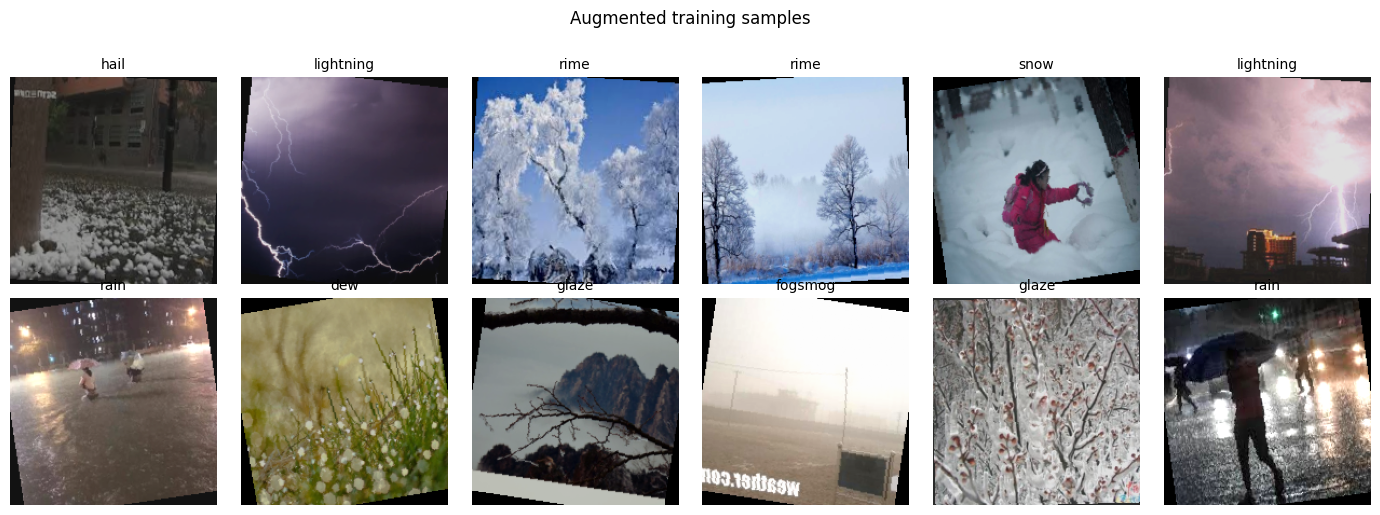

In [6]:
def denorm(t):
    m = torch.tensor(mean).view(3, 1, 1); s = torch.tensor(std).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lbl in zip(axes.ravel(), xb[:12], yb[:12]):
    ax.imshow(denorm(img)); ax.set_title(class_names[lbl], fontsize=10); ax.axis("off")
plt.suptitle("Augmented training samples", y=1.02); plt.tight_layout(); plt.show()

## 4. Define CNN Architecture

A custom **ResNet-style CNN** built from scratch: a convolutional stem followed by **7 residual blocks** in 4 stages, global average pooling and a small classifier head.

| Design choice | Justification |
|---|---|
| **Residual (skip) connections** | The block learns `F(x) + x`. The identity path lets gradients flow straight to earlier layers, which makes a deeper network easier to optimise and reduces the vanishing-gradient problem. |
| **Two 3x3 convs per block** | Small filters give a large receptive field with few parameters and extra non-linearity. |
| **1x1 projection shortcut when the shape changes** | When a block changes the channel count or halves the resolution, a 1x1 conv on the skip path makes the shapes match so the addition is possible. |
| **Stride-2 convolution for down-sampling** | A learnable down-sampling step instead of fixed max-pooling; the first conv of the block halves the resolution. |
| **Channels 32 -> 64 -> 128 -> 256** | Resolution halves at each stage while channels double: early layers capture edges/colour/texture, deeper layers capture larger structures such as sky, fog layers or snow cover. |
| **BatchNorm after every conv** | Stabilises and speeds up training, allows a higher learning rate, and acts as a mild regulariser. |
| **ReLU** | Cheap, non-saturating non-linearity. |
| **Global Average Pooling** | Replaces a huge flatten + FC layer, cutting parameters and making the model independent of input size. |
| **Dropout 0.3 before the classifier** | Regularisation against over-fitting on a small dataset. |
| **Kaiming initialisation** | Initialisation designed for ReLU networks, keeps activation variance stable. |
| **Final Linear layer with one output per class** | Outputs raw logits; `CrossEntropyLoss` applies softmax internally. |

In [7]:
class ResBlock(nn.Module):
    """conv3x3-BN-ReLU -> conv3x3-BN, add shortcut, ReLU"""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)
        if stride != 1 or in_ch != out_ch:                      
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))               

class WeatherResNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(                              # 192x192
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.layers = nn.Sequential(
            ResBlock(32, 32, 1),                                # 192x192
            ResBlock(32, 64, 2), ResBlock(64, 64, 1),           # 96x96
            ResBlock(64, 128, 2), ResBlock(128, 128, 1),        # 48x48
            ResBlock(128, 256, 2), ResBlock(256, 256, 1),       # 24x24
        )
        self.gap  = nn.AdaptiveAvgPool2d(1)                     # 24x24 -> 1x1
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.gap(self.layers(self.stem(x))))

model = WeatherResNet(NUM_CLASSES).to(device)
print(model)

WeatherResNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (layers): Sequential(
    (0): ResBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): ResBlock(
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kerne

In [8]:
def model_summary(model, input_size=(3, IMG_SIZE, IMG_SIZE)):
    rows, hooks = [], []
    def hook(module, inp, out):
        if len(list(module.children())) == 0:                   
            params = sum(p.numel() for p in module.parameters())
            rows.append((module.__class__.__name__, tuple(out.shape[1:]), params))
    for m in model.modules(): hooks.append(m.register_forward_hook(hook))
    was_training = model.training; model.eval()
    with torch.no_grad(): model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks: h.remove()

    print("=" * 66); print(f"{'Layer':<22}{'Output shape':<26}{'Params':>12}"); print("=" * 66)
    for name, shape, p in rows: print(f"{name:<22}{str(shape):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("=" * 66)
    print(f"Total params     : {total:,}"); print(f"Trainable params : {trainable:,}")
    print(f"Approx. size     : {total * 4 / 1024**2:.2f} MB (float32)"); print("=" * 66)

model_summary(model)

Layer                 Output shape                    Params
Conv2d                (32, 192, 192)                     864
BatchNorm2d           (32, 192, 192)                      64
ReLU                  (32, 192, 192)                       0
Conv2d                (32, 192, 192)                   9,216
BatchNorm2d           (32, 192, 192)                      64
ReLU                  (32, 192, 192)                       0
Conv2d                (32, 192, 192)                   9,216
BatchNorm2d           (32, 192, 192)                      64
Identity              (32, 192, 192)                       0
ReLU                  (32, 192, 192)                       0
Conv2d                (64, 96, 96)                    18,432
BatchNorm2d           (64, 96, 96)                       128
ReLU                  (64, 96, 96)                         0
Conv2d                (64, 96, 96)                    36,864
BatchNorm2d           (64, 96, 96)                       128
Conv2d                (6

## 5. Training Loop with Validation

### Hyperparameters and rationale

| Hyperparameter | Value | Rationale |
|---|---|---|
| Loss | `CrossEntropyLoss` (label smoothing 0.1) | Standard for multi-class classification; smoothing reduces over-confidence, which helps with visually ambiguous weather images. |
| Optimizer | **AdamW** | Adam with *decoupled* weight decay: adaptive learning rates for fast convergence, with a cleaner L2-style regularisation than plain Adam. |
| Peak learning rate | 2e-3 | Works well with AdamW + BatchNorm + residual connections. |
| Weight decay | 1e-2 | Regularisation to limit over-fitting on a small dataset. |
| LR scheduler | **OneCycleLR** (25% warm-up, then cosine decay) | LR rises to the peak, then anneals to almost zero. Fast progress early and fine convergence at the end; the schedule is fixed in advance, so no early stopping is needed. |
| Gradient clipping | max-norm 1.0 | Prevents rare exploding gradients at the high-LR phase. |
| Batch size | 64 | Stable gradients and fits easily in GPU memory. |
| Epochs | 50 | Enough for the one-cycle schedule to converge on a dataset of this size. |
| Input resolution | 192x192 | Keeps the fine texture detail that separates the icy classes (frost, rime, glaze). |
| Test-time augmentation | horizontal flip | Averages the predictions for an image and its mirror image. It is fixed in advance, so nothing is tuned on the test set. |
| Mixed precision (AMP) | enabled on GPU | Faster training and lower memory with no meaningful accuracy loss. |
| Model selection | best **validation accuracy** checkpoint | The test set is never used for selection. |

In [9]:
EPOCHS          = 50
MAX_LR          = 2e-3
WEIGHT_DECAY    = 1e-2
LABEL_SMOOTHING = 0.1

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, epochs=EPOCHS,
                                          steps_per_epoch=len(train_loader), pct_start=0.25)

use_amp = device.type == "cuda"
scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train=True):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if train: optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out  = model(x)
                loss = criterion(out, y)
            if train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
                scheduler.step()                            
            total_loss += loss.item() * x.size(0)
            correct    += (out.argmax(1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
best_val_acc, best_state = 0.0, None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    flag = ""
    if va_acc > best_val_acc:                       
        best_val_acc, best_state = va_acc, copy.deepcopy(model.state_dict()); flag = " <- best"

    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {history['lr'][-1]:.1e}{flag}")

print(f"\nTraining time: {(time.time() - start) / 60:.1f} min | Best val accuracy: {best_val_acc:.4f}")
model.load_state_dict(best_state)                  

Epoch 01/50 | train loss 1.9157 acc 0.4185 | val loss 1.6383 acc 0.4976 | lr 1.1e-04 <- best
Epoch 02/50 | train loss 1.6060 acc 0.5188 | val loss 1.5158 acc 0.5374 | lr 2.0e-04 <- best
Epoch 03/50 | train loss 1.5418 acc 0.5431 | val loss 1.5272 acc 0.5481 | lr 3.4e-04 <- best
Epoch 04/50 | train loss 1.5083 acc 0.5558 | val loss 1.5459 acc 0.5666 | lr 5.3e-04 <- best
Epoch 05/50 | train loss 1.4923 acc 0.5740 | val loss 1.4792 acc 0.5957 | lr 7.4e-04 <- best
Epoch 06/50 | train loss 1.4376 acc 0.6010 | val loss 1.4949 acc 0.5870 | lr 9.8e-04
Epoch 07/50 | train loss 1.4638 acc 0.5821 | val loss 1.6243 acc 0.5510 | lr 1.2e-03
Epoch 08/50 | train loss 1.4107 acc 0.6219 | val loss 1.4381 acc 0.6268 | lr 1.5e-03 <- best
Epoch 09/50 | train loss 1.3798 acc 0.6369 | val loss 1.4868 acc 0.5918 | lr 1.7e-03
Epoch 10/50 | train loss 1.3590 acc 0.6406 | val loss 1.5299 acc 0.5734 | lr 1.8e-03
Epoch 11/50 | train loss 1.3466 acc 0.6442 | val loss 1.4091 acc 0.6317 | lr 1.9e-03 <- best
Epoch 12/

<All keys matched successfully>

## 6. Evaluate Model on Test Set

In [10]:
@torch.no_grad()
def predict(loader, net=None, tta=True):
    """Class predictions. With tta=True the softmax of an image and of its horizontal mirror are averaged."""
    net = net or model
    net.eval(); preds, labels = [], []
    for x, y in loader:
        x = x.to(device)
        p = torch.softmax(net(x).float(), 1)
        if tta:
            p = (p + torch.softmax(net(torch.flip(x, dims=[3])).float(), 1)) / 2
        preds.append(p.argmax(1).cpu()); labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

y_pred_plain, y_true = predict(test_loader, tta=False)
test_acc_plain = accuracy_score(y_true, y_pred_plain)
y_pred, _ = predict(test_loader, tta=True)
test_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Test accuracy without TTA : {test_acc_plain * 100:.2f}%")
print(f"Test accuracy (flip-TTA)  : {test_acc * 100:.2f}%   <- reported result")
print(f"Macro F1-score (TTA): {macro_f1:.4f}   (average of the per-class F1, treats every class equally - useful because classes are imbalanced)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Test accuracy without TTA : 85.92%
Test accuracy (flip-TTA)  : 86.31%   <- reported result
Macro F1-score (TTA): 0.8659   (average of the per-class F1, treats every class equally - useful because classes are imbalanced)

              precision    recall  f1-score   support

         dew     0.9083    0.9429    0.9252       105
     fogsmog     0.9008    0.9219    0.9112       128
       frost     0.7391    0.7183    0.7286        71
       glaze     0.6893    0.7396    0.7136        96
        hail     0.9512    0.8764    0.9123        89
   lightning     0.9492    1.0000    0.9739        56
        rain     0.8701    0.8481    0.8590        79
     rainbow     1.0000    0.9143    0.9552        35
        rime     0.8404    0.9080    0.8729       174
   sandstorm     0.9400    0.9038    0.9216       104
        snow     0.8125    0.6989    0.7514        93

    accuracy                         0.8631      1030
   macro avg     0.8728    0.8611    0.8659      1030
weighted avg     0.86

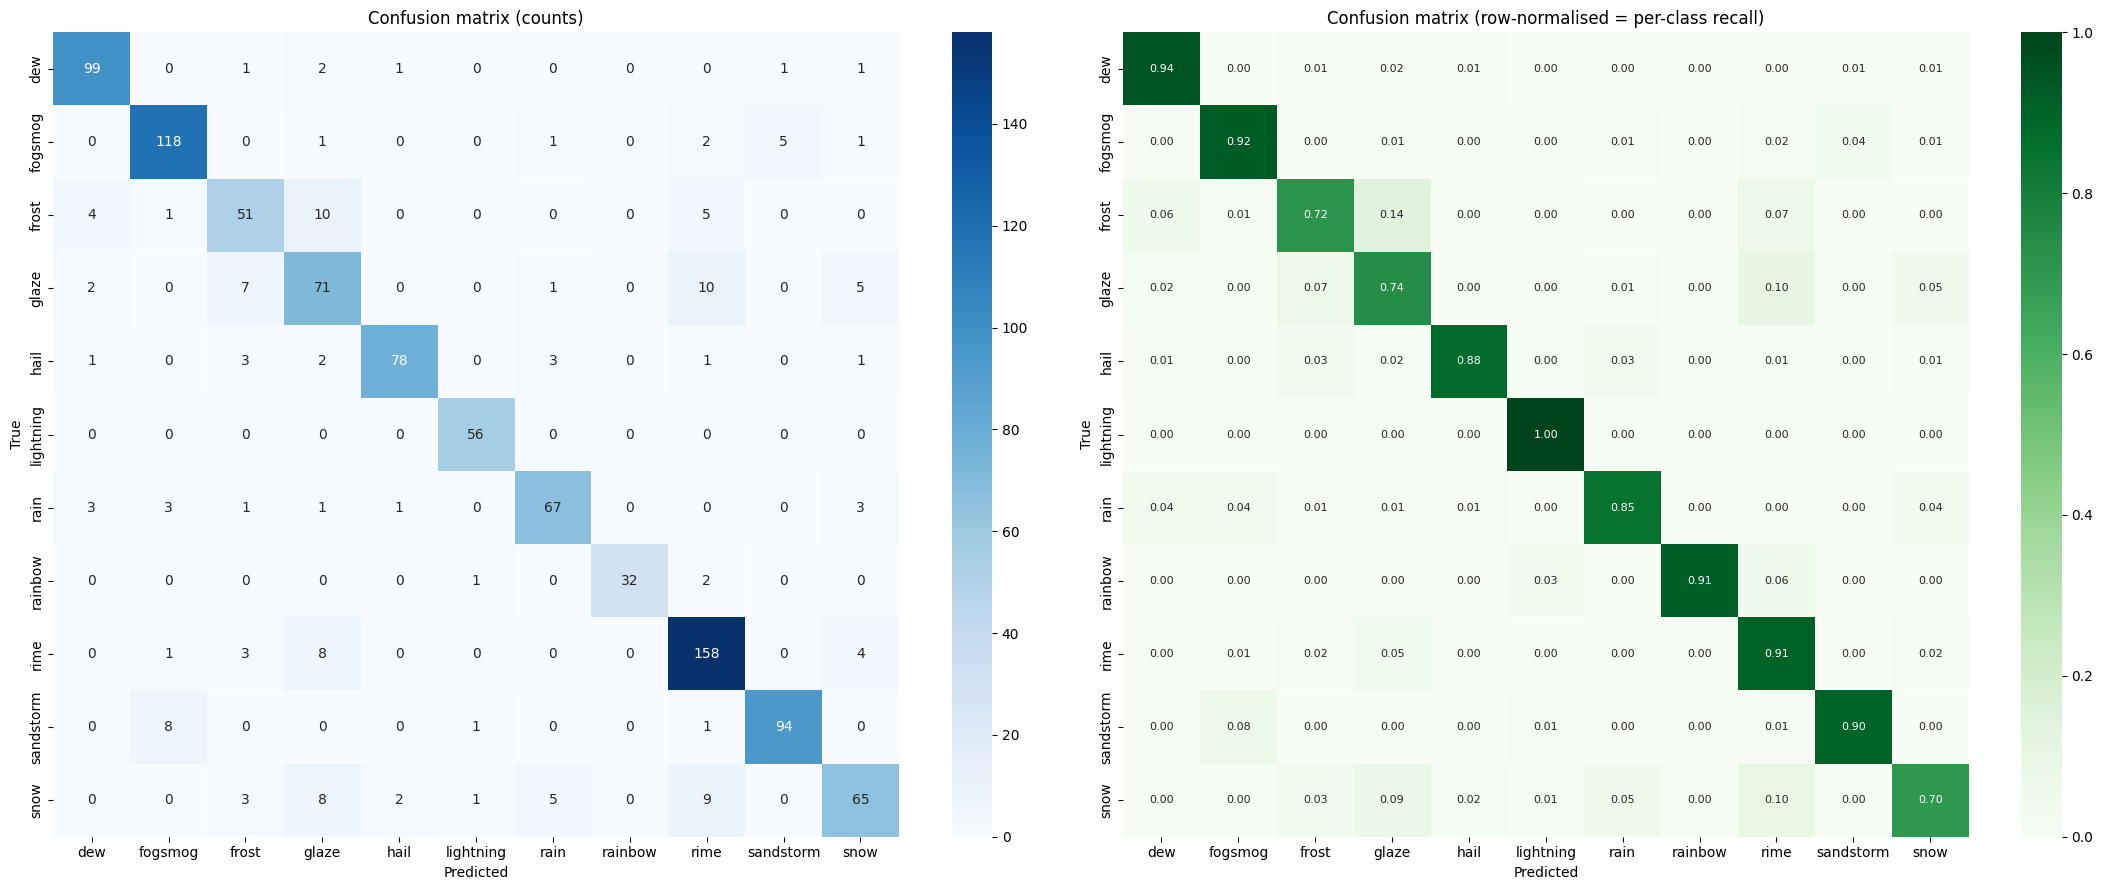

Top confusions (true -> predicted : count):
       frost -> glaze     : 10
       glaze -> rime      : 10
        snow -> rime      : 9
        rime -> glaze     : 8
   sandstorm -> fogsmog   : 8
        snow -> glaze     : 8
       glaze -> frost     : 7
     fogsmog -> sandstorm : 5


In [11]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="Greens",
            xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalised = per-class recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.show()

pairs = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
top_pairs = [p for p in sorted(pairs, key=lambda r: -r[2]) if p[2] > 0][:8]
print("Top confusions (true -> predicted : count):")
for t, p, c in top_pairs: print(f"  {t:>10} -> {p:<10}: {c}")

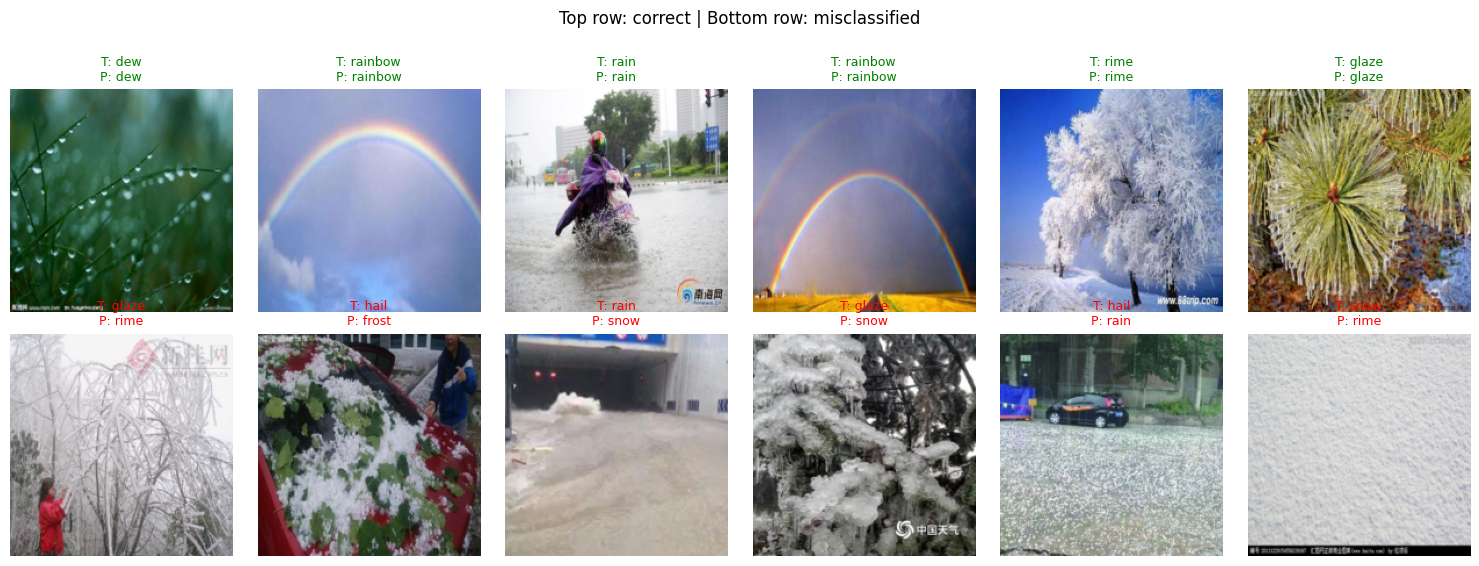

In [12]:
def collect_samples(loader, preds, max_each=6):
    """Correct / wrong examples, using the same predictions (y_pred) as the metrics above."""
    good, bad, k = [], [], 0
    for x, y in loader:
        for img, t in zip(x, y):
            q = int(preds[k]); k += 1
            (good if t.item() == q else bad).append((img, t.item(), q))
        if len(good) >= max_each and len(bad) >= max_each: break
    return good[:max_each], bad[:max_each]

good, bad = collect_samples(test_loader, y_pred)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, (samples, color) in enumerate([(good, "green"), (bad, "red")]):
    for col in range(6):
        ax = axes[row, col]; ax.axis("off")
        if col < len(samples):
            img, t, q = samples[col]
            ax.imshow(denorm(img)); ax.set_title(f"T: {class_names[t]}\nP: {class_names[q]}", color=color, fontsize=9)
plt.suptitle("Top row: correct | Bottom row: misclassified", y=1.02); plt.tight_layout(); plt.show()

## 7. Visualizations (Loss/Accuracy Curves)

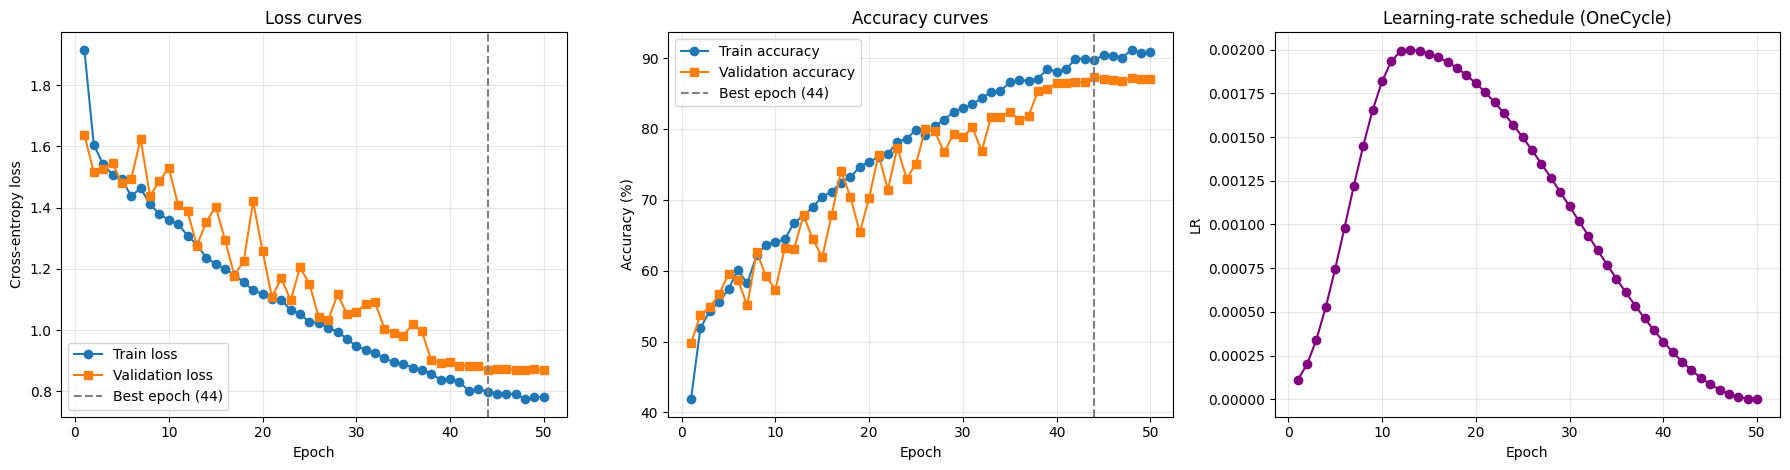

In [13]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
best_ep = int(np.argmax(history["val_acc"])) + 1

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(epochs_ran, history["train_loss"], "o-", label="Train loss")
ax[0].plot(epochs_ran, history["val_loss"],   "s-", label="Validation loss")
ax[0].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
ax[0].set_title("Loss curves"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epochs_ran, np.array(history["train_acc"]) * 100, "o-", label="Train accuracy")
ax[1].plot(epochs_ran, np.array(history["val_acc"]) * 100,   "s-", label="Validation accuracy")
ax[1].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
ax[1].set_title("Accuracy curves"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].legend(); ax[1].grid(alpha=.3)

ax[2].plot(epochs_ran, history["lr"], "o-", c="purple")
ax[2].set_title("Learning-rate schedule (OneCycle)"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("LR"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

In [14]:
tl, vl, ta, va, lr = (np.array(history[k]) for k in ["train_loss", "val_loss", "train_acc", "val_acc", "lr"])
min_vl_ep = int(vl.argmin()) + 1
peak_lr_ep = int(lr.argmax()) + 1
notes = [
    f"Loss: training loss fell from {tl[0]:.3f} (epoch 1) to {tl[-1]:.3f} (epoch {len(tl)}); validation loss fell from {vl[0]:.3f} to {vl[-1]:.3f}, "
    f"with its minimum ({vl.min():.3f}) at epoch {min_vl_ep}.",
    f"Accuracy: training accuracy rose from {ta[0]:.1%} to {ta[-1]:.1%}; validation accuracy rose from {va[0]:.1%} to {va[-1]:.1%} "
    f"and peaked at {va.max():.1%} in epoch {best_ep}.",
    f"Learning rate: OneCycleLR warmed up to about {lr.max():.1e} around epoch {peak_lr_ep} and then annealed to {lr[-1]:.1e} by the last epoch.",
]
if vl[-1] > vl.min() * 1.10:
    notes.append("Validation loss ended more than 10% above its minimum, a sign of mild over-fitting in the last epochs; the best-validation-accuracy checkpoint is what is evaluated on the test set.")
else:
    notes.append("Validation loss stayed close to its minimum until the end, so there is no clear sign of over-fitting.")
if ta[-1] < va[-1]:
    notes.append("Training accuracy stays below validation accuracy because the training batches are augmented and use dropout and label smoothing, while validation images are clean.")
for n in notes:
    print(textwrap.fill(n, 110)); print()

Loss: training loss fell from 1.916 (epoch 1) to 0.783 (epoch 50); validation loss fell from 1.638 to 0.869,
with its minimum (0.869) at epoch 50.

Accuracy: training accuracy rose from 41.9% to 90.9%; validation accuracy rose from 49.8% to 87.1% and peaked
at 87.4% in epoch 44.

Learning rate: OneCycleLR warmed up to about 2.0e-03 around epoch 13 and then annealed to 8.6e-09 by the last
epoch.

Validation loss stayed close to its minimum until the end, so there is no clear sign of over-fitting.



## 8. Analysis & Discussion of Results

In [15]:
per_class_recall = cm.diagonal() / cm.sum(1)
order = np.argsort(per_class_recall)
weakest   = [(class_names[i], per_class_recall[i]) for i in order[:3]]
strongest = [(class_names[i], per_class_recall[i]) for i in order[::-1][:3]]
gap = history["train_acc"][best_ep - 1] - history["val_acc"][best_ep - 1]
total_params = sum(p.numel() for p in model.parameters())
val_test_diff = abs(best_val_acc - test_acc)
small_idx = int(class_counts.argmin())

print("=" * 62); print("RESULTS SUMMARY"); print("=" * 62)
print(f"Dataset            : Weather image dataset ({NUM_CLASSES} classes, {len(all_targets)} images)")
print(f"Train/Val/Test     : {len(train_set)} / {len(val_set)} / {len(test_set)}")
print(f"Parameters         : {total_params:,}")
print(f"Epochs run         : {len(history['train_loss'])} (best epoch = {best_ep})")
print(f"Train accuracy     : {history['train_acc'][best_ep-1]*100:.2f}%  (at best epoch)")
print(f"Validation accuracy: {best_val_acc*100:.2f}%")
print(f"TEST accuracy      : {test_acc*100:.2f}%  (with flip test-time augmentation)")
print(f"TEST acc. no TTA   : {test_acc_plain*100:.2f}%")
print(f"TEST macro F1      : {macro_f1:.4f}")
print(f"Train-Val gap      : {gap*100:+.2f} pts")
print(f"Best classes       : " + ", ".join(f"{n} ({r:.1%})" for n, r in strongest))
print(f"Weakest classes    : " + ", ".join(f"{n} ({r:.1%})" for n, r in weakest))
print("=" * 62 + "\n")

report = []
report.append(f"Overall performance. The ResNet-style CNN, trained from scratch (no pre-trained weights), reached {test_acc:.2%} test accuracy (horizontal-flip test-time augmentation; {test_acc_plain:.2%} without it) "
              f"and a macro F1-score of {macro_f1:.3f} on {len(test_set)} unseen images, against a best validation accuracy of {best_val_acc:.2%}.")
if val_test_diff <= 0.015:
    report.append(f"Validation and test accuracy differ by only {val_test_diff*100:.2f} points, so the model generalises to unseen data and the validation set was a reliable guide for choosing the checkpoint.")
else:
    report.append(f"Validation and test accuracy differ by {val_test_diff*100:.2f} points. With a dataset of this size the two subsets can differ in difficulty, so the test figure is the more honest estimate.")
if gap < -0.005:
    report.append(f"Training accuracy at the best epoch ({history['train_acc'][best_ep-1]:.2%}) is lower than validation accuracy; this is expected because training images are augmented and the network uses dropout and label smoothing, which make the training task harder than clean validation images.")
elif gap <= 0.03:
    report.append(f"The train-validation gap at the best epoch is only {gap*100:.2f} points, so over-fitting is limited.")
else:
    report.append(f"The train-validation gap at the best epoch is {gap*100:.2f} points, which indicates a degree of over-fitting; stronger augmentation, more dropout or more data would be the next steps.")
report.append("Per-class behaviour. The classes recognised best are " + ", ".join(f"{n} ({r:.1%} recall)" for n, r in strongest) +
              ", while the hardest are " + ", ".join(f"{n} ({r:.1%} recall)" for n, r in weakest) + ".")
if top_pairs:
    report.append("The most frequent mistakes (true -> predicted, number of test images) are: " + "; ".join(f"{t} -> {p} ({c})" for t, p, c in top_pairs[:4]) +
                  ". Look at the misclassified examples above to see why: these weather conditions often share similar colours, textures or lighting.")
rec_small = per_class_recall[small_idx]
if rec_small < test_acc:
    report.append(f"Class imbalance. The smallest class ({class_names[small_idx]}, {class_counts[small_idx]} images in total) has recall {rec_small:.1%}, below the overall accuracy, which is consistent with it having fewer training examples.")
else:
    report.append(f"Class imbalance. Even the smallest class ({class_names[small_idx]}, {class_counts[small_idx]} images in total) reaches {rec_small:.1%} recall, so the imbalance did not noticeably hurt it; macro F1 ({macro_f1:.3f}) is reported alongside accuracy to treat all classes equally.")
for r in report:
    print(textwrap.fill(r, 110)); print()

RESULTS SUMMARY
Dataset            : Weather image dataset (11 classes, 6862 images)
Train/Val/Test     : 4803 / 1029 / 1030
Parameters         : 2,779,307
Epochs run         : 50 (best epoch = 44)
Train accuracy     : 89.71%  (at best epoch)
Validation accuracy: 87.37%
TEST accuracy      : 86.31%  (with flip test-time augmentation)
TEST acc. no TTA   : 85.92%
TEST macro F1      : 0.8659
Train-Val gap      : +2.34 pts
Best classes       : lightning (100.0%), dew (94.3%), fogsmog (92.2%)
Weakest classes    : snow (69.9%), frost (71.8%), glaze (74.0%)

Overall performance. The ResNet-style CNN, trained from scratch (no pre-trained weights), reached 86.31% test
accuracy (horizontal-flip test-time augmentation; 85.92% without it) and a macro F1-score of 0.866 on 1030
unseen images, against a best validation accuracy of 87.37%.

Validation and test accuracy differ by only 1.06 points, so the model generalises to unseen data and the
validation set was a reliable guide for choosing the checkp

### Discussion

**Observations from the confusion matrix.** The weakest classes are snow, frost and glaze, and the largest confusions are frost -> glaze (10 images), glaze -> rime (10), snow -> rime (9) and rime -> glaze (8). All of these are cold-weather conditions with white or translucent, icy surfaces. They differ mainly in fine surface texture (a thin frozen layer, ice crystals, or a snow cover), which is easily lost at 192x192 resolution and is hard to separate even for a human. In contrast, lightning (100% recall), dew and fog/smog have very distinctive colours or shapes and are recognised almost perfectly.

**Effect of the design choices.**
- *Residual connections + BatchNorm* make the network easy to optimise; training loss fell steadily, while validation loss and accuracy were noisy as long as the learning rate was high (roughly epochs 5-35) and settled as the learning rate was annealed.
- *AdamW + OneCycleLR* gave quick progress at the start and fine convergence at the end of the fixed 50-epoch schedule, so no early stopping was required. The best-validation-accuracy checkpoint is the model that is tested.
- *Augmentation, dropout, label smoothing and weight decay* work together as regularisation on a relatively small dataset.
- *Stratified splits* keep the same class proportions in train, validation and test, which makes the per-class results comparable.
- *Macro F1 next to accuracy* is reported because the classes are not perfectly balanced.
- *192x192 input and flip test-time augmentation* were chosen to help the visually similar icy classes; the plain and TTA test accuracies printed above show how much the TTA step changes the result: in this run it changed the test accuracy from 85.92% to 86.31%.

**Limitations.**
- Images are down-sampled to 192x192, which still discards some fine detail (for example the crystal structure that separates frost, rime and glaze).
- The model was trained once with one seed and one random split; results can vary by a little between runs and splits.
- The dataset is small and some labels are visually ambiguous (a scene can show fog *and* rain), which limits the accuracy that any model can reach.
- Photographs come from a limited set of sources, so performance on very different camera types or regions is unknown.

## 9. Conclusions & Future Work

### Conclusions
- A custom ResNet-style CNN with residual blocks, BatchNorm, global average pooling and dropout was built from scratch and trained on a weather image dataset (see the results summary in Section 8 for the final accuracy and macro F1).
- AdamW, label-smoothed cross-entropy, a OneCycle learning-rate schedule, data augmentation and a stratified train/validation/test split gave steady training progress (validation fluctuated during the high-learning-rate phase and then settled); the model was selected on validation accuracy and evaluated once on the untouched test set.
- The remaining errors are concentrated in the classes listed in the analysis above, which are visually similar to other weather conditions.
- The trained weights are saved as a compact `.pth` file and verified to reload with identical test predictions.

### Future work
1. **Transfer learning** with a pre-trained backbone (ResNet-18/50, EfficientNet, MobileNet), usually a clear accuracy gain on small datasets.
2. **Even higher input resolution** (e.g. 256 px or more) to keep fine texture details.
3. **Stronger augmentation** (MixUp, CutMix, RandAugment) aimed at the weak classes (snow, frost, glaze). Class re-weighting is less relevant here because the smallest class (rainbow) is already recognised well.
4. **Hyperparameter search** and **k-fold cross-validation** for more robust estimates.
5. **Explainability** with Grad-CAM to check that the network looks at the sky/ground regions that define each weather type.
6. **Ensembling** several models or **multi-crop test-time augmentation** for extra accuracy (only flip test-time augmentation is used here).

## 10. Save and Load Trained Model Weights (.pth)

Only the `state_dict` (the learned weights) is saved. This is the recommended PyTorch practice because it is portable and not tied to a specific file layout. The class names and preprocessing constants are stored with it. We then reload it into a fresh model and confirm the test predictions are identical.

In [16]:
MODEL_PATH = "cnn_weather_best.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "mean": mean, "std": std,
    "test_accuracy": float(test_acc),
}, MODEL_PATH)

size_mb = os.path.getsize(MODEL_PATH) / 1024**2
print(f"Saved '{MODEL_PATH}'  ({size_mb:.2f} MB)")
print("OK to upload to GitHub (< 20 MB)." if size_mb < 20 else "Larger than 20 MB -> keep a LOCAL copy, do NOT upload to GitHub.")

Saved 'cnn_weather_best.pth'  (10.66 MB)
OK to upload to GitHub (< 20 MB).


In [17]:
ckpt = torch.load(MODEL_PATH, map_location=device)
loaded = WeatherResNet(len(ckpt["class_names"])).to(device)
loaded.load_state_dict(ckpt["model_state_dict"]); loaded.eval()

yp2, yt2 = predict(test_loader, net=loaded)
print(f"Reloaded-model test accuracy: {accuracy_score(yt2, yp2) * 100:.2f}%  (original: {test_acc * 100:.2f}%)")
assert np.array_equal(yp2, y_pred), "Predictions differ after reload!"
print("Predictions identical after save/load. OK")

Reloaded-model test accuracy: 86.31%  (original: 86.31%)
Predictions identical after save/load. OK


True label: frost


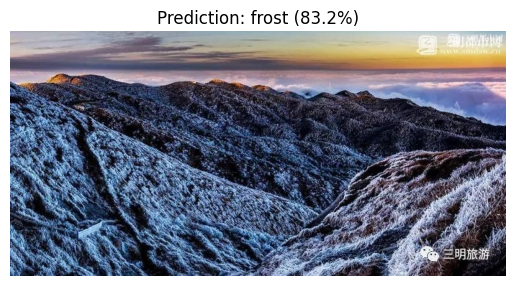

[('frost', 83.24), ('rime', 9.2), ('rainbow', 1.73)]


In [18]:
def predict_image(path, topk=3):
    img = Image.open(path).convert("RGB")
    x = eval_tfms(img).unsqueeze(0).to(device)
    with torch.no_grad(): probs = torch.softmax(loaded(x), 1)[0].cpu()
    vals, idxs = probs.topk(topk)
    plt.imshow(img); plt.axis("off"); plt.title(f"Prediction: {class_names[idxs[0]]} ({vals[0]*100:.1f}%)"); plt.show()
    return [(class_names[i], round(v.item() * 100, 2)) for v, i in zip(vals, idxs)]

k = int(random.choice(test_idx))
sample_path, true_label = eval_ds_full.samples[k]
print("True label:", class_names[true_label])
print(predict_image(sample_path))